In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from marathon_predictor.config import PROCESSED_DIR



In [3]:
df = pd.read_parquet(PROCESSED_DIR / "berlin.parquet")
df.head()

,year,gender,nationality,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
0,1999,M,KEN,909.0,1821.0,2725.0,3634.0,3834.0,4494.0,5410.0,6305.0,7208.0,7604.0
1,1999,M,JPN,909.0,1821.0,2727.0,3636.0,3834.0,4496.0,5418.0,6321.0,7218.0,7617.0
2,1999,M,KEN,910.0,1821.0,2727.0,3635.0,3834.0,4495.0,5418.0,6359.0,7301.0,7711.0
3,1999,M,MAR,911.0,1823.0,2727.0,3636.0,3835.0,4496.0,5424.0,6374.0,7372.0,7796.0
4,1999,M,KEN,910.0,1821.0,0.0,3635.0,3835.0,4495.0,5418.0,6374.0,7378.0,7837.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 678711 entries, 0 to 678710
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   year         678711 non-null  int64  
 1   gender       678709 non-null  str    
 2   nationality  678694 non-null  str    
 3   split_5k     678656 non-null  float64
 4   split_10k    678667 non-null  float64
 5   split_15k    678633 non-null  float64
 6   split_20k    678628 non-null  float64
 7   time_half    678664 non-null  float64
 8   split_25k    678634 non-null  float64
 9   split_30k    678658 non-null  float64
 10  split_35k    678651 non-null  float64
 11  split_40k    647940 non-null  float64
 12  time_full    678711 non-null  float64
dtypes: float64(10), int64(1), str(2)
memory usage: 70.1 MB


In [6]:
df.describe()

,year,split_5k,split_10k,split_15k,split_20k,time_half,split_25k,split_30k,split_35k,split_40k,time_full
count,678711.000000,678656.000000,678667.000000,678633.000000,678628.000000,678664.000000,678634.000000,678658.000000,678651.000000,647940.000000,678711.000000
mean,2009.982586,1652.467144,3344.612529,5013.524624,6708.805945,7152.524902,8537.386774,10350.829293,12112.245450,14078.806939,14912.177041
std,5.920815,294.391893,527.544458,801.529492,1086.343230,1182.213176,1453.280976,1796.713359,2426.964996,2497.949842,2582.195770
min,1999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.000000,1492.000000,2991.000000,4477.000000,5976.000000,6335.000000,7538.000000,9116.000000,10692.000000,12386.000000,13112.000000
50%,2010.000000,1660.000000,3331.000000,4985.000000,6659.000000,7071.000000,8422.000000,10189.000000,11971.000000,13816.000000,14623.000000
75%,2015.000000,1833.000000,3681.000000,5514.000000,7379.000000,7886.000000,9426.000000,11447.000000,13524.000000,15614.000000,16519.000000
max,2019.000000,4215.000000,7158.000000,10539.000000,14142.000000,18217.000000,42113.000000,21847.000000,25787.000000,29777.000000,31639.000000


In [5]:
df.isna().sum()

year               0
gender             2
nationality       17
split_5k          55
split_10k         44
split_15k         78
split_20k         83
time_half         47
split_25k         77
split_30k         53
split_35k         60
split_40k      30771
time_full          0
dtype: int64

The split at 40k seems to be missing for a lot of runners. Apart from that, almost all splits are available for further analysis.

In [19]:
sum(df["split_5k"] < 12 * 60)

6356

In [13]:
sum(df["split_5k"] > df["split_10k"])

629

Text(0.5, 1.0, 'Distribution of finish times')

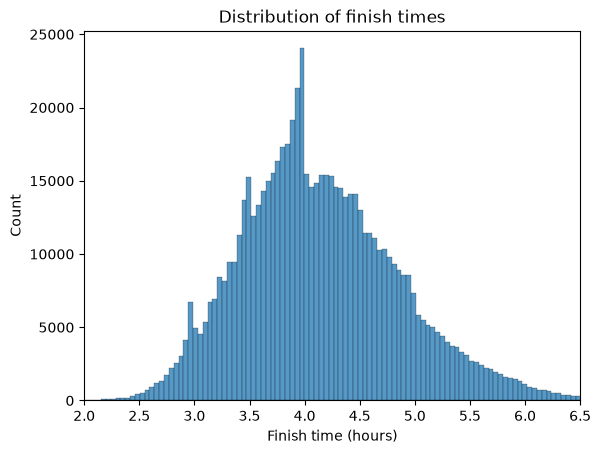

In [20]:
ax = sns.histplot(df["time_full"] / 3600, bins=200)
ax.set_xlabel("Finish time (hours)")
ax.set_ylabel("Count")
ax.set_xlim(2, 6.5)
ax.set_title("Distribution of finish times")


One can clearly see that there are a lot more runners finishing a few minutes below for example 3, 3.5, 4, 4.5, 5 hours than there are finishing a little bit over these times.

<Axes: title={'center': 'Number of runners per year'}, xlabel='year'>

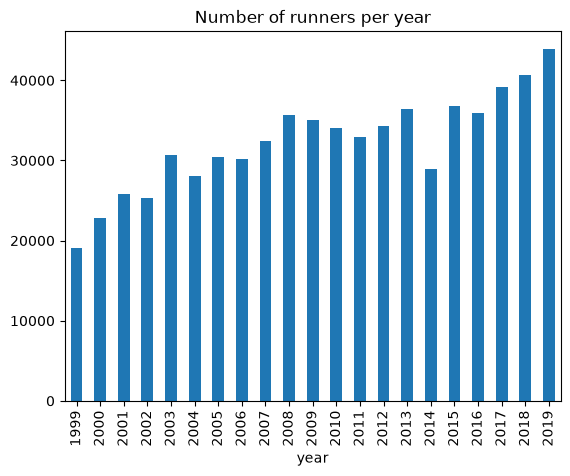

In [24]:
runners_per_year = df.groupby("year").size()
runners_per_year.plot(kind="bar", title="Number of runners per year")

There is a clear upwards trend in the number of finishers of the Berlin marathon over the years. 

<Axes: title={'center': 'Ratio of women per year'}, xlabel='year'>

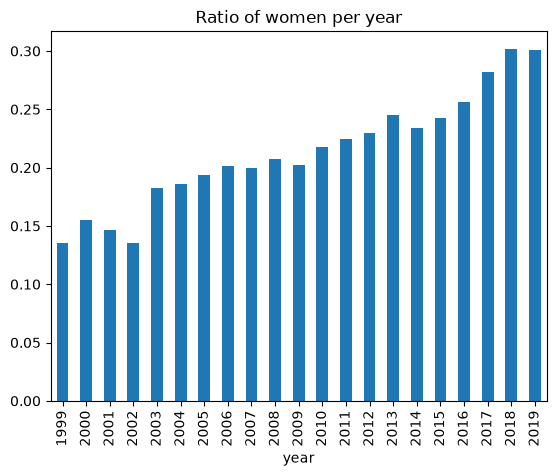

In [28]:
women_per_year = df[df["gender"] == "F"].groupby("year").size()
women_ratio_per_year = women_per_year / runners_per_year
women_ratio_per_year.plot(kind="bar", title="Ratio of women per year")

The ratio of women finishing the marathon is increasing over the years.

In [36]:
time_full = df["time_full"] 
time_half = df["time_half"]
time_second_half = time_full - time_half

negative_split_times = sum(time_second_half < time_half)
negative_split_ratio = negative_split_times / len(df)
print(f"{round(negative_split_ratio*100,3)}% of runners had a negative split (second half faster than first half).")

16.313% of runners had a negative split (second half faster than first half).


In [ ]:
ratio_ten_percent_slower_than_first_half = sum(time_second_half > 1.1 * time_half) / len(df)
print(f"{round(ratio_ten_percent_slower_than_first_half*100,3)}% of runners had a split that was 10% slower than the first half.")



38.48% of runners had a split that was 10% slower than the first half.


In [47]:
ratio_ten_percent_slower_than_first_half_women = sum(time_second_half[df["gender"] == "F"] > 1.1 * time_half[df["gender"] == "F"]) / len(df[df["gender"] == "F"])
ratio_ten_percent_slower_than_first_half_men = sum(time_second_half[df["gender"] == "M"] > 1.1 * time_half[df["gender"] == "M"]) / len(df[df["gender"] == "M"])
print(f"{round(ratio_ten_percent_slower_than_first_half_women*100,3)}% of women had a split that was 10% slower than the first half.")
print(f"{round(ratio_ten_percent_slower_than_first_half_men*100,3)}% of men had a split that was 10% slower than the first half.")




33.259% of women had a split that was 10% slower than the first half.
39.962% of men had a split that was 10% slower than the first half.


Men have a higher higher percentage of slowing down more than 10% in the second half then women. 